Question 76. Create plots that could help managers improve purchase ratings and purchases.

Original dataset:


,ID,Age,Income,Spending Score,Region,Category,Visits,Online Time,Purchase,Rating
0,1,22,25000,65,North,Grocery,5,12,Yes,4.2
1,2,35,55000,40,West,Electronics,2,8,No,3.8
2,3,28,32000,70,South,Clothing,6,15,Yes,4.5
3,4,45,75000,30,East,Grocery,3,6,No,3.5
4,5,30,60000,80,South,Electronics,7,18,Yes,4.8
5,6,26,40000,55,North,Clothing,4,10,Yes,4.1
6,7,38,50000,45,West,Grocery,3,9,No,3.9
7,8,29,45000,75,South,Electronics,6,16,Yes,4.6
8,9,50,80000,35,West,Clothing,2,5,No,3.6
9,10,33,52000,60,North,Grocery,5,11,Yes,4.3


,PurchaseRate,MeanRating,Customers
Category,,,
Clothing,0.666667,4.066667,3
Electronics,0.666667,4.400000,3
Grocery,0.500000,3.975000,4


,PurchaseRate,MeanRating,Customers
Region,,,
East,0.0,3.500000,1
North,1.0,4.200000,3
South,1.0,4.633333,3
West,0.0,3.766667,3


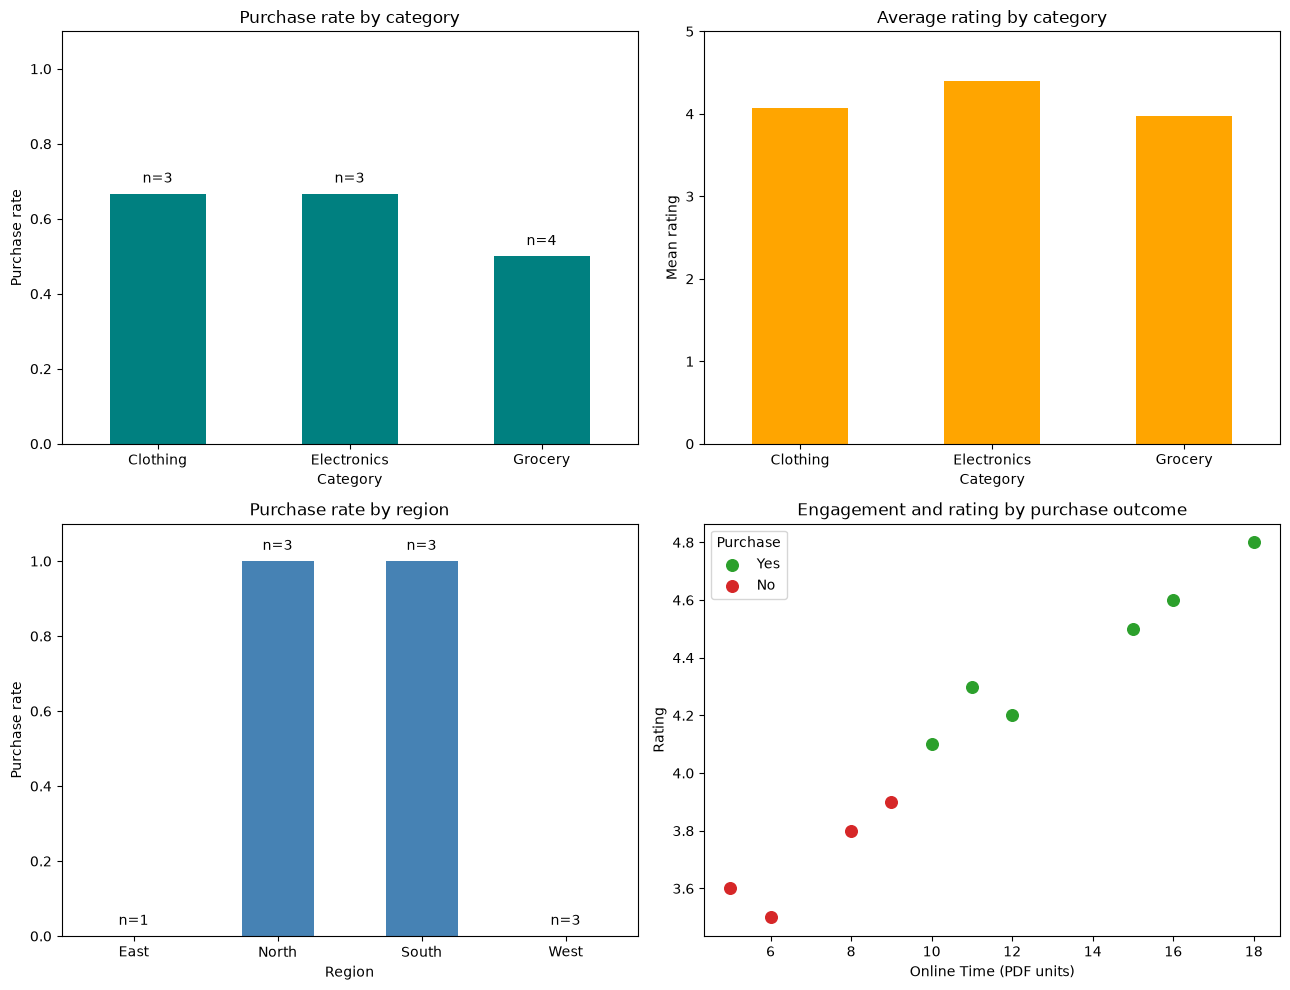

Saved question76_plot.png


In [ ]:
# Step 1: Import the libraries needed for this program.
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Step 2: Load the CSV file from this question's folder into a DataFrame (table).
df = pd.read_csv("Customer_PurchaseData.csv")
print("Original dataset:")
display(df)

# Step 3: Represent Yes as 1 and No as 0, so the mean gives the purchase rate.
df["Purchased"] = df["Purchase"].eq("Yes").astype(int)

# Step 4: Summarise purchase rate, average rating and sample size for each category.
category = df.groupby("Category").agg(
    PurchaseRate=("Purchased", "mean"), MeanRating=("Rating", "mean"), Customers=("ID", "size")
)

# Step 5: Calculate the same management measures for each region.
region = df.groupby("Region").agg(
    PurchaseRate=("Purchased", "mean"), MeanRating=("Rating", "mean"), Customers=("ID", "size")
)

# Step 6: Create a four-panel management dashboard.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# Step 7: Compare category conversion rates and show sample sizes.
category["PurchaseRate"].plot.bar(ax=axes[0, 0], rot=0, color="teal")
axes[0, 0].set(title="Purchase rate by category", xlabel="Category", ylabel="Purchase rate", ylim=(0, 1.1))
for i, row in enumerate(category.itertuples()):
    axes[0, 0].text(i, row.PurchaseRate + 0.03, f"n={row.Customers}", ha="center")

# Step 8: Compare average customer ratings by category.
category["MeanRating"].plot.bar(ax=axes[0, 1], rot=0, color="orange")
axes[0, 1].set(title="Average rating by category", xlabel="Category", ylabel="Mean rating", ylim=(0, 5))

# Step 9: Compare regional purchase rates, again showing sample sizes.
region["PurchaseRate"].plot.bar(ax=axes[1, 0], rot=0, color="steelblue")
axes[1, 0].set(title="Purchase rate by region", xlabel="Region", ylabel="Purchase rate", ylim=(0, 1.1))
for i, row in enumerate(region.itertuples()):
    axes[1, 0].text(i, row.PurchaseRate + 0.03, f"n={row.Customers}", ha="center")

# Step 10: Compare online engagement and ratings for purchasers and non-purchasers.
for purchase, colour in [("Yes", "tab:green"), ("No", "tab:red")]:
    group = df.loc[df["Purchase"] == purchase]
    axes[1, 1].scatter(group["Online Time"], group["Rating"], c=colour, label=purchase, s=70)
axes[1, 1].set(title="Engagement and rating by purchase outcome", xlabel="Online Time (PDF units)", ylabel="Rating")
axes[1, 1].legend(title="Purchase")

# Step 11: Display and export the management summaries.
display(category, region)
category.to_csv("category_management_summary.csv")
region.to_csv("region_management_summary.csv")

# Final step: Arrange labels, save the chart and display it below this cell.
fig.tight_layout()
fig.savefig("question76_plot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved question76_plot.png")


Interpretation / method

Managers could investigate low-conversion categories/regions and engagement patterns, and collect more representative data before interventions. North/South versus West/East is perfectly confounded with purchase outcome here. Small sample sizes are labelled; these charts are exploratory and do not justify causal claims or regional targeting by themselves.